# Tutorial: import an LW-DETR ONNX model into Aidge

This notebook shows the complete validation workflow used in this project:

1. load one exported ONNX model;
2. run it with ONNX Runtime as the reference;
3. import the same graph into Aidge;
4. fuse the exported arithmetic patterns into native `SDShiftGELU`, `SDShiftSiLU`, and `SDShiftmax` operators;
5. inspect native coverage and tensor dtypes;
6. run Aidge and compare its final outputs with ONNX Runtime.

> Run this notebook with the **`aidge`** kernel. A full LW-DETR graph is large: ONNX import and Aidge inference can each take some time on CPU.

## 1. Configuration

Only edit this cell for normal use. Paths are resolved from the repository root even when Jupyter starts inside `experiments/`.

In [ ]:
from pathlib import Path

cwd = Path.cwd().resolve()
REPO_ROOT = cwd.parent if cwd.name in {"experiments", "deploy"} else cwd

# Choose one exported model. The fake-quant model contains the arithmetic
# patterns that the Aidge fusion recipes recognize.
MODEL_PATH = REPO_ROOT / "output/export_tiny_ptq/inference_model.sim.onnx"
IMAGE_DIR = REPO_ROOT / "demo/images"
IMAGE_INDEX = 0
IMAGE_SIZE = 640
AIDGE_BACKEND = "cpu"

# This is the dtype requested during Aidge propagation. It is not a guarantee
# that every imported fake-quant tensor becomes int8; inspect the report below.
AIDGE_DTYPE = None  # set below after importing aidge_core

assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"
assert IMAGE_DIR.exists(), f"Image directory not found: {IMAGE_DIR}"
print("repository:", REPO_ROOT)
print("model:     ", MODEL_PATH)
print("images:    ", IMAGE_DIR)

repository: /home/tl286648/dev/model/LW-DETR
model:      /home/tl286648/dev/model/LW-DETR/output/export_tiny_ptq/inference_model.sim.onnx
images:     /home/tl286648/dev/model/LW-DETR/demo/images


## 2. Imports and environment check

Importing `aidge_backend_cpu` is important: the import registers the CPU implementations with Aidge. If it is omitted, execution may fail with a *missing or invalid registrar key* error.

In [ ]:
import time
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import onnxruntime as ort
from matplotlib import patches
from PIL import Image

import aidge_core
import aidge_onnx
import aidge_backend_cpu  # noqa: F401 -- registers CPU implementations

AIDGE_DTYPE = aidge_core.dtype.int32
aidge_core.Log.set_console_level(aidge_core.Level.Error)
print("ONNX Runtime providers:", ort.get_available_providers())
print("Aidge tensor backends:  ", aidge_core.Tensor.get_available_backends())

Running cmake --build & --install in /home/tl286648/dev/aidge_project/aidge/aidge/aidge_core/build
Running cmake --build & --install in /home/tl286648/dev/aidge_project/aidge/aidge/aidge_backend_cpu/build
ONNX Runtime providers: ['AzureExecutionProvider', 'CPUExecutionProvider']
Aidge tensor backends:   {'cpu', 'export_serialize'}


## 3. Load and preprocess an image

LW-DETR uses a square resize followed by ImageNet normalization. Both runtimes must receive exactly the same `float32` input array for a meaningful comparison.

image: 000000062808.jpg (640, 481)
input: (1, 3, 640, 640) float32


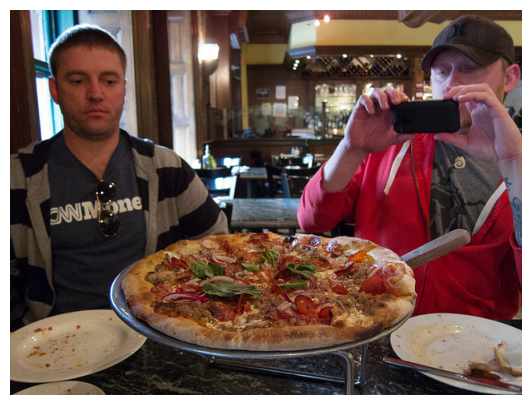

In [ ]:
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32).reshape(3, 1, 1)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32).reshape(3, 1, 1)


def preprocess(image, image_size=IMAGE_SIZE):
    resized = image.resize((image_size, image_size), Image.Resampling.BILINEAR)
    hwc = np.asarray(resized, dtype=np.float32) / 255.0
    chw = np.transpose(hwc, (2, 0, 1))
    return ((chw - MEAN) / STD)[None].astype(np.float32)


image_paths = sorted(
    path
    for path in IMAGE_DIR.iterdir()
    if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)
assert image_paths, f"No test images found in {IMAGE_DIR}"
assert IMAGE_INDEX < len(image_paths), (IMAGE_INDEX, len(image_paths))

image_path = image_paths[IMAGE_INDEX]
image = Image.open(image_path).convert("RGB")
input_array = preprocess(image)

print("image:", image_path.name, image.size)
print("input:", input_array.shape, input_array.dtype)
plt.figure(figsize=(7, 5))
plt.imshow(image)
plt.axis("off")
plt.show()

## 4. Run ONNX Runtime

ONNX Runtime is our reference implementation. Keep its output names because Aidge output nodes are not guaranteed to have the same friendly names.

In [ ]:
ort_session = ort.InferenceSession(
    str(MODEL_PATH), providers=["CPUExecutionProvider"]
)
ort_input_name = ort_session.get_inputs()[0].name
ort_output_names = [output.name for output in ort_session.get_outputs()]

t0 = time.perf_counter()
ort_values = ort_session.run(None, {ort_input_name: input_array})
ort_outputs = dict(zip(ort_output_names, ort_values))
print(f"ONNX Runtime forward: {time.perf_counter() - t0:.3f}s")
for name, value in ort_outputs.items():
    print(f"  {name:<20} shape={value.shape} dtype={value.dtype}")

ONNX Runtime forward: 3.536s
  dets                 shape=(1, 100, 4) dtype=float32
  labels               shape=(1, 100, 91) dtype=float32


## 5. Import and prepare the Aidge graph

The ONNX file initially contains decomposed arithmetic. The three recipes recognize the complete exported patterns and replace them with native operators. For the tiny model used here, the expected counts are normally **6 SDShiftGELU**, **8 SDShiftSiLU**, and **12 SDShiftmax**.

`forward_dtype()` propagates a requested execution dtype; it does not recover per-layer precision metadata from ONNX and does not guarantee that every tensor becomes int8. The current imported model needs this call for valid implementation selection, but its fake-quant data path remains `float32`. Consequently, fused SD nodes use their float boundary adapters, which convert represented values to integer codes, execute the integer kernel, and convert the result back to the surrounding float representation. Always confirm the actual result with the dtype report below.

In [ ]:
t0 = time.perf_counter()
aidge_model = aidge_onnx.load_onnx(str(MODEL_PATH))
print(f"Aidge ONNX import: {time.perf_counter() - t0:.3f}s")

t0 = time.perf_counter()
aidge_core.recipes.fuse_sd_shift_gelu(aidge_model)
aidge_core.recipes.fuse_sd_shift_silu(aidge_model)
aidge_core.recipes.fuse_sd_shiftmax(aidge_model)
aidge_core.recipes.fuse_sd_layernorm(aidge_model)
print(f"SD fusion recipes: {time.perf_counter() - t0:.3f}s")

type_counts = Counter(node.type() for node in aidge_model.get_nodes())
print("SDShiftGELU nodes:", type_counts["SDShiftGELU"])
print("SDShiftSiLU nodes:", type_counts["SDShiftSiLU"])
print("SDShiftmax nodes: ", type_counts["SDShiftmax"])
print("SDLayerNorm nodes:", type_counts["SDLayerNorm"])

aidge_model.forward_dtype(dtype=AIDGE_DTYPE)
aidge_model.set_backend(AIDGE_BACKEND)
aidge_scheduler = aidge_core.SequentialScheduler(aidge_model)

Aidge ONNX import: 17.849s
SD fusion recipes: 4.609s
SDShiftGELU nodes: 6
SDShiftSiLU nodes: 8
SDShiftmax nodes:  12
SDLayerNorm nodes: 24


## 6. Native coverage and dtype reports

Native coverage tells us whether the ONNX importer created generic fallback operators. The dtype report below counts output tensors; it is more useful than printing thousands of nodes individually.

In [ ]:
aidge_onnx.native_coverage_report(aidge_model)

dtype_counts = Counter()
operator_dtype_counts = Counter()
for node in aidge_model.get_nodes():
    op = node.get_operator()
    for index in range(op.nb_outputs()):
        tensor = op.get_output(index)
        dtype_counts[str(tensor.dtype)] += 1
        operator_dtype_counts[(node.type(), str(tensor.dtype))] += 1

print("\nOutput tensor dtypes:")
for dtype, count in dtype_counts.most_common():
    print(f"  {dtype:<20} {count}")

print("\nFused SD operator dtypes:")
for (op_type, dtype), count in sorted(operator_dtype_counts.items()):
    if op_type in {"SDShiftGELU", "SDShiftSiLU", "SDShiftmax", "SDLayerNorm"}:
        print(f"  {op_type:<16} {dtype:<20} {count}")

Native operators: 4913 (39 types)
- Add: 148
- And: 9
- Cast: 344
- Clip: 213
- Concat: 14
- Conv2D: 5
- Cos: 4
- Div: 549
- Expand: 4
- Floor: 16
- Gather: 46
- GatherElements: 4
- Greater: 2
- GreaterOrEqual: 6
- LessOrEqual: 6
- MatMul: 82
- Max: 2
- Mul: 610
- PaddedConv2D: 6
- Pow: 4
- Producer: 1896
- ReLU: 8
- ReduceMax: 1
- ReduceSum: 3
- Reshape: 93
- Round: 639
- SDLayerNorm: 24
- SDShiftGELU: 6
- SDShiftSiLU: 8
- SDShiftmax: 12
- Sin: 4
- Slice: 26
- Split: 1
- Sub: 18
- Tile: 1
- TopK: 1
- Transpose: 53
- Unsqueeze: 44
- Where: 1
Generic operators: 0 (0 types)
Native types coverage: 100.0% (39/39)
Native operators coverage: 100.0% (4913/4913)

Output tensor dtypes:
  dtype.float32        3611
  dtype.float64        996
  dtype.int64          275
  dtype.boolean        33

Fused SD operator dtypes:
  SDLayerNorm      dtype.float32        24
  SDShiftGELU      dtype.float32        6
  SDShiftSiLU      dtype.float32        8
  SDShiftmax       dtype.float32        12


## 7. Run Aidge

The model input remains a normalized `float32` image. Aidge routes tensors according to the imported graph and dtype propagation configured above. `forward(False, ...)` avoids intentionally retaining every intermediate output. Reading the final outputs is inexpensive compared with executing the model.

In [ ]:
def collect_aidge_outputs(model):
    return [
        np.array(node.get_operator().get_output(output_index))
        for node, output_index in model.get_ordered_outputs()
    ]


def map_outputs_by_unique_shape(raw_outputs, reference_outputs):
    mapped = {}
    unused = set(range(len(raw_outputs)))
    for name, reference in reference_outputs.items():
        candidates = [
            index for index in unused
            if raw_outputs[index].shape == reference.shape
        ]
        if len(candidates) != 1:
            raise RuntimeError(
                f"Cannot map output {name!r} by shape {reference.shape}: "
                f"candidates={candidates}. Inspect get_ordered_outputs()."
            )
        index = candidates[0]
        mapped[name] = raw_outputs[index]
        unused.remove(index)
    return mapped


aidge_input = aidge_core.Tensor(input_array)
aidge_input.to_dtype(aidge_core.dtype.float32)
t0 = time.perf_counter()
aidge_scheduler.forward(False, [aidge_input])
print(f"Aidge forward: {time.perf_counter() - t0:.3f}s")

raw_aidge_outputs = collect_aidge_outputs(aidge_model)
aidge_outputs = map_outputs_by_unique_shape(raw_aidge_outputs, ort_outputs)
for name, value in aidge_outputs.items():
    print(f"  {name:<20} shape={value.shape} dtype={value.dtype}")

Aidge forward: 15.390s
  dets                 shape=(1, 100, 4) dtype=float32
  labels               shape=(1, 100, 91) dtype=float32


## 8. Compare final tensors

Exact equality is not always expected: ONNX Runtime executes the decomposed fake-quant graph, while Aidge executes fused native integer arithmetic through float graph boundaries. Nevertheless, large errors are not automatically acceptable—they can indicate a fusion, scale, dtype-propagation, or kernel mismatch. Report the numerical error and inspect whether the resulting detections remain consistent before considering the import validated.

In [ ]:
for name, reference in ort_outputs.items():
    candidate = aidge_outputs[name]
    assert candidate.shape == reference.shape, (name, candidate.shape, reference.shape)
    difference = np.abs(
        candidate.astype(np.float64) - reference.astype(np.float64)
    )
    print(name)
    print(f"  max absolute error:  {difference.max():.8g}")
    print(f"  mean absolute error: {difference.mean():.8g}")
    print(f"  median error:        {np.median(difference):.8g}")

dets
  max absolute error:  0.97077364
  mean absolute error: 0.17244825
  median error:        0.10219457
labels
  max absolute error:  6.234699
  mean absolute error: 0.72453491
  median error:        0.57043135


## 9. Plot detections side by side

The exported LW-DETR model returns `dets` in normalized `cx, cy, width, height` format and `labels` as class logits.

ONNX Runtime detections:
  person           score=0.8767 box=[ -1.5   2.  282.1 406. ]
  person           score=0.8496 box=[342.7  -1.4 644.2 395. ]
  pizza            score=0.7623 box=[140.1 276.5 514.7 424.1]
  cell phone       score=0.6339 box=[477.7 110.9 562.2 157.1]

Aidge detections:
  person           score=0.9139 box=[ -2.3   9.2 281.3 413.2]
  pizza            score=0.7932 box=[124.3 276.2 516.1 432.6]
  person           score=0.7519 box=[355.9   0.7 642.7 398.2]


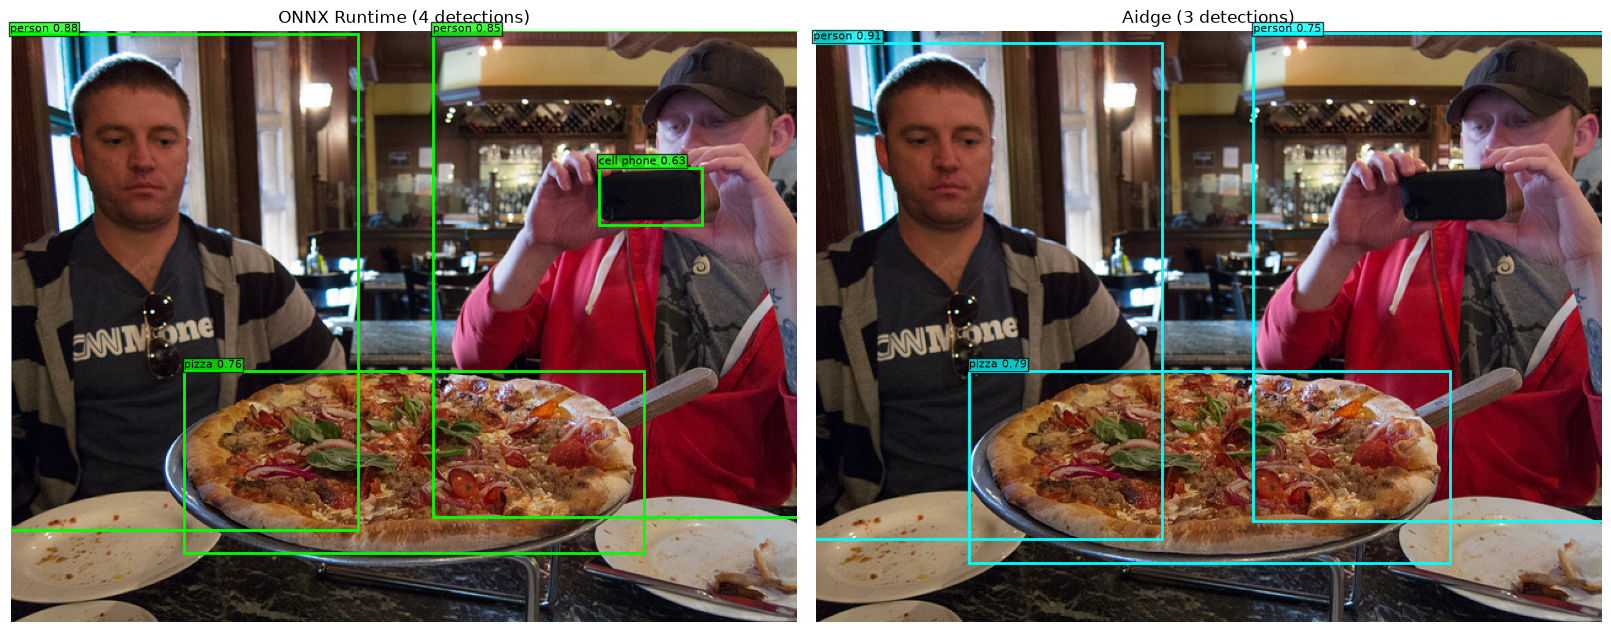

In [ ]:
COCO_NAMES = {
    1: "person", 2: "bicycle", 3: "car", 4: "motorcycle",
    5: "airplane", 6: "bus", 7: "train", 8: "truck",
    9: "boat", 10: "traffic light", 11: "fire hydrant",
    13: "stop sign", 14: "parking meter", 15: "bench",
    16: "bird", 17: "cat", 18: "dog", 19: "horse",
    20: "sheep", 21: "cow", 22: "elephant", 23: "bear",
    24: "zebra", 25: "giraffe", 27: "backpack",
    28: "umbrella", 31: "handbag", 32: "tie", 33: "suitcase",
    34: "frisbee", 35: "skis", 36: "snowboard",
    37: "sports ball", 38: "kite", 39: "baseball bat",
    40: "baseball glove", 41: "skateboard", 42: "surfboard",
    43: "tennis racket", 44: "bottle", 46: "wine glass",
    47: "cup", 48: "fork", 49: "knife", 50: "spoon",
    51: "bowl", 52: "banana", 53: "apple", 54: "sandwich",
    55: "orange", 56: "broccoli", 57: "carrot",
    58: "hot dog", 59: "pizza", 60: "donut", 61: "cake",
    62: "chair", 63: "couch", 64: "potted plant", 65: "bed",
    67: "dining table", 70: "toilet", 72: "tv",
    73: "laptop", 74: "mouse", 75: "remote", 76: "keyboard",
    77: "cell phone", 78: "microwave", 79: "oven",
    80: "toaster", 81: "sink", 82: "refrigerator",
    84: "book", 85: "clock", 86: "vase", 87: "scissors",
    88: "teddy bear", 89: "hair drier", 90: "toothbrush",
}


def sigmoid(value):
    return 1.0 / (1.0 + np.exp(-value))


def detections_from_outputs(outputs, image_size, threshold=0.5, limit=20):
    logits = outputs["labels"][0]
    boxes = outputs["dets"][0]
    scores = sigmoid(logits).reshape(-1)
    class_count = logits.shape[-1]
    width, height = image_size
    result = []
    for flat_index in np.argsort(scores)[::-1]:
        score = float(scores[flat_index])
        if score < threshold or len(result) >= limit:
            break
        box_index = int(flat_index // class_count)
        label = int(flat_index % class_count)
        cx, cy, box_width, box_height = boxes[box_index]
        xyxy = np.array([
            cx - box_width / 2, cy - box_height / 2,
            cx + box_width / 2, cy + box_height / 2,
        ]) * np.array([width, height, width, height])
        result.append((score, label, xyxy))
    return result


def draw(ax, detections, title, color):
    ax.imshow(image)
    ax.set_title(f"{title} ({len(detections)} detections)")
    ax.axis("off")
    for score, label, (x0, y0, x1, y1) in detections:
        rectangle = patches.Rectangle(
            (x0, y0), x1 - x0, y1 - y0,
            linewidth=2, edgecolor=color, facecolor="none",
        )
        ax.add_patch(rectangle)
        ax.text(
            x0, max(0, y0 - 3),
            f"{COCO_NAMES.get(label, f'class_{label}')} {score:.2f}",
            fontsize=8, color="black",
            bbox={"facecolor": color, "alpha": 0.75, "pad": 1},
        )


ort_detections = detections_from_outputs(ort_outputs, image.size)
aidge_detections = detections_from_outputs(aidge_outputs, image.size)
print("ONNX Runtime detections:")
for score, label, box in ort_detections:
    print(f"  {COCO_NAMES.get(label, f'class_{label}'):<16} "
          f"score={score:.4f} box={np.round(box, 1)}")
print("\nAidge detections:")
for score, label, box in aidge_detections:
    print(f"  {COCO_NAMES.get(label, f'class_{label}'):<16} "
          f"score={score:.4f} box={np.round(box, 1)}")

fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
draw(axes[0], ort_detections, "ONNX Runtime", "lime")
draw(axes[1], aidge_detections, "Aidge", "cyan")
plt.show()

## 10. Profile Aidge by operator, stage, and transformer block

Scheduling entries contain `duration_ns`. Besides individual operators, LW-DETR node names preserve their module path, for example `encoder_blocks_3` and `transformer_decoder_layers_1`. We can therefore aggregate kernel time into the backbone encoder, projector, transformer decoder, and prediction heads, then split the encoder and decoder into individual blocks.

These values are sums of scheduled node durations, not a second forward pass. Their total can differ slightly from wall-clock latency because Python, scheduler, allocation, and output-collection overhead are outside the node measurements.

In [ ]:
import re

by_type = defaultdict(float)
individual = []
for item in aidge_scheduler.get_forward_scheduling():
    seconds = item.duration_ns / 1e9
    individual.append((seconds, item.node.type(), item.node.name()))
    by_type[item.node.type()] += seconds

print("Slowest nodes:")
for seconds, op_type, name in sorted(individual, reverse=True)[:15]:
    print(f"  {seconds:9.4f}s  {op_type:<18} {name}")

print("\nTime by operator type:")
for op_type, seconds in sorted(by_type.items(), key=lambda item: item[1], reverse=True)[:15]:
    print(f"  {seconds:9.4f}s  {op_type}")


# Aidge converts ONNX paths such as /transformer/decoder/layers.2/...
# into names containing transformer_decoder_layers_2_.... Keep the
# expressions narrow so unrelated nodes containing 'encoder' or 'head'
# are not silently assigned to the wrong stage.
ENCODER_BLOCK = re.compile(r'(?:^|_)encoder_blocks_(\d+)(?:_|$)')
DECODER_BLOCK = re.compile(r'(?:^|_)decoder_layers_(\d+)(?:_|$)')
PROJECTOR_TOKEN = 'backbone_backbone_0_projector'
PREDICTION_HEAD_TOKENS = (
    'bbox_embed', 'class_embed', 'enc_out_bbox_embed',
    'enc_out_class_embed',
)


def model_region(node_name):
    encoder_match = ENCODER_BLOCK.search(node_name)
    if encoder_match:
        index = int(encoder_match.group(1))
        return 'Encoder', f'Encoder block {index + 1}'

    if PROJECTOR_TOKEN in node_name:
        return 'Projector', None

    decoder_match = DECODER_BLOCK.search(node_name)
    if decoder_match:
        index = int(decoder_match.group(1))
        return 'Decoder', f'Decoder block {index + 1}'

    if any(token in node_name for token in PREDICTION_HEAD_TOKENS):
        return 'Prediction heads', None

    return 'Other / graph plumbing', None


by_stage = defaultdict(float)
stage_nodes = Counter()
by_block = defaultdict(float)
block_nodes = Counter()

for seconds, _, name in individual:
    stage, block = model_region(name)
    by_stage[stage] += seconds
    stage_nodes[stage] += 1
    if block is not None:
        by_block[block] += seconds
        block_nodes[block] += 1

scheduled_seconds = sum(by_stage.values())
stage_order = (
    'Encoder', 'Projector', 'Decoder', 'Prediction heads',
    'Other / graph plumbing',
)
print(f'\nTime by major model stage (scheduled total {scheduled_seconds:.4f}s):')
for stage in stage_order:
    seconds = by_stage.get(stage, 0.0)
    percent = 100.0 * seconds / scheduled_seconds if scheduled_seconds else 0.0
    print(
        f'  {stage:<24} {seconds:9.4f}s  {percent:6.2f}%  '
        f'{stage_nodes.get(stage, 0):5d} nodes'
    )

print('\nTime inside encoder blocks:')
for block in sorted(
    (name for name in by_block if name.startswith('Encoder')),
    key=lambda name: int(name.rsplit(' ', 1)[1]),
):
    print(f'  {block:<24} {by_block[block]:9.4f}s  {block_nodes[block]:5d} nodes')

print('\nTime inside decoder blocks:')
for block in sorted(
    (name for name in by_block if name.startswith('Decoder')),
    key=lambda name: int(name.rsplit(' ', 1)[1]),
):
    print(f'  {block:<24} {by_block[block]:9.4f}s  {block_nodes[block]:5d} nodes')

Slowest nodes:
     0.4023s  SDShiftmax         backbone_backbone_0_encoder_blocks_1_attn_softmax_Mul_8_SDShiftmax
     0.3956s  SDShiftmax         backbone_backbone_0_encoder_blocks_5_attn_softmax_Mul_8_SDShiftmax
     0.3938s  SDShiftmax         backbone_backbone_0_encoder_blocks_3_attn_softmax_Mul_8_SDShiftmax
     0.1638s  Round              backbone_backbone_0_encoder_blocks_3_attn_qact_attn_out_Round_2
     0.1622s  Cast               backbone_backbone_0_encoder_blocks_3_attn_qact_qk_matmul_out_Cast
     0.1606s  Cast               backbone_backbone_0_encoder_blocks_1_attn_qact_attn_out_Cast
     0.1603s  Mul                backbone_backbone_0_encoder_blocks_3_attn_qact_attn_out_Mul_1
     0.1601s  Cast               backbone_backbone_0_encoder_blocks_1_attn_qact_qk_matmul_out_Cast
     0.1596s  Cast               backbone_backbone_0_encoder_blocks_3_attn_qact_attn_out_Cast
     0.1592s  Round              backbone_backbone_0_encoder_blocks_1_attn_qact_qk_matmul_out_Round_2
     

## 11. Optional: visualize the graph

A full LW-DETR graph is very large and can make the browser UI slow. Prefer the small component notebooks in `experiments/` when learning the graph viewer.

Uncomment only one visualization call. If the GUI is closed and cannot start a second time, restart the Jupyter kernel so the previous server/port is released.

In [ ]:
# from aidge_gui import visualize
# visualize(aidge_model)

# Alternatively:
# import aidge_model_explorer
# aidge_model_explorer.visualize(aidge_model, "lwdetr_imported_onnx")

## 12. Four-way output, image, and execution-time comparison

This section compares the checkpoint in PyTorch, ONNX Runtime, the imported unfused Aidge arithmetic graph, and the fused Aidge graph. PyTorch runs in the repository's `lwdetr2` environment through a small helper because the Aidge Python 3.12 environment does not contain PyTorch.

Timing covers forward execution only. Model construction, checkpoint loading, ONNX import, fusion, dtype propagation, backend selection, output conversion, and plotting are excluded. Full-model CPU inference is slow, so the tutorial defaults to one timed run with no warm-up. Increase both values when you need a statistically stable benchmark.

**Numerical warning:** this ONNX is a fake-quant float-carrier graph, but the current workaround sets `AIDGE_DTYPE=int8` for the complete graph. The unfused generic operators and fused SD integer kernels therefore do not have explicit QuantAct/requantization boundaries and scales between every layer. These Aidge runs profile execution, but they are not yet a valid proof of fused-versus-unfused numerical equivalence.

In [ ]:
import subprocess
import sys

PYTORCH_PYTHON = Path('/home/tl286648/miniforge3/envs/lwdetr2/bin/python')
CHECKPOINT_PATH = REPO_ROOT / 'pretrain_weights/coco/tiny/ilwdetr_ptq.pth'
PYTORCH_RUNNER = REPO_ROOT / 'experiments/profile_pytorch_lwdetr.py'
PROFILE_DIR = REPO_ROOT / 'experiments/profile_artifacts'
PROFILE_DIR.mkdir(parents=True, exist_ok=True)
PROFILE_INPUT = PROFILE_DIR / 'lwdetr_input.npy'
PYTORCH_PROFILE = PROFILE_DIR / 'pytorch_outputs.npz'
PROFILE_WARMUP = 0
PROFILE_RUNS = 1

assert PYTORCH_PYTHON.exists(), PYTORCH_PYTHON
assert CHECKPOINT_PATH.exists(), CHECKPOINT_PATH
assert PYTORCH_RUNNER.exists(), PYTORCH_RUNNER
np.save(PROFILE_INPUT, input_array)
command = [
    str(PYTORCH_PYTHON), str(PYTORCH_RUNNER),
    '--checkpoint', str(CHECKPOINT_PATH),
    '--input', str(PROFILE_INPUT),
    '--output', str(PYTORCH_PROFILE),
    '--warmup', str(PROFILE_WARMUP),
    '--runs', str(PROFILE_RUNS),
]
subprocess.run(command, cwd=REPO_ROOT, check=True)
pytorch_data = np.load(PYTORCH_PROFILE)
pytorch_outputs = {
    'dets': pytorch_data['dets'],
    'labels': pytorch_data['labels'],
}
pytorch_latency = float(pytorch_data['latency_seconds'])
print(f'PyTorch forward: {pytorch_latency:.6f}s average')

/home/tl286648/miniforge3/envs/lwdetr2/lib/python3.8/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


Configured quantized export model: softmax_count=12, softmax_calibrate_m=True
Fused blocks: 0
Skipped (BN but missing conv): 0
Reshaped compatible checkpoint tensors: 201 scalar/vector buffer(s).
First reshaped tensors: [('transformer.decoder.layers.0.self_attn.matmul.act_scaling_factor', ()), ('transformer.decoder.layers.1.self_attn.matmul.act_scaling_factor', ()), ('transformer.decoder.layers.2.self_attn.matmul.act_scaling_factor', ()), ('transformer.decoder.qact_sine_embed.act_scale_mantissa', ()), ('transformer.decoder.qact_sine_embed.act_scale_shift', ()), ('transformer.decoder.qact_norm_output.act_scale_mantissa', ()), ('transformer.decoder.qact_norm_output.act_scale_shift', ()), ('transformer.qact_post_linear_output.1.act_scale_mantissa', ()), ('transformer.qact_post_linear_output.1.act_scale_shift', ()), ('transformer.qact_post_linear_output.2.act_scale_mantissa', ()), ('transformer.qact_post_linear_output.2.act_scale_shift', ()), ('transformer.qact_post_linear_output.3.act_sca

/home/tl286648/miniforge3/envs/lwdetr2/lib/python3.8/site-packages/torch/functional.py:513: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3609.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


{"latency_seconds": 3.9221733286976814, "runs": 1}
PyTorch forward: 3.922173s average


In [ ]:
def average_seconds(function, warmup=PROFILE_WARMUP, runs=PROFILE_RUNS):
    for _ in range(warmup):
        function()
    start = time.perf_counter()
    for _ in range(runs):
        function()
    return (time.perf_counter() - start) / runs


run_ort = lambda: ort_session.run(None, {ort_input_name: input_array})
ort_latency = average_seconds(run_ort)
ort_values = run_ort()
profile_ort_outputs = dict(zip(ort_output_names, ort_values))

unfused_model = aidge_onnx.load_onnx(str(MODEL_PATH))
unfused_model.forward_dtype(dtype=AIDGE_DTYPE)
unfused_model.set_backend(AIDGE_BACKEND)
unfused_scheduler = aidge_core.SequentialScheduler(unfused_model)
unfused_input = aidge_core.Tensor(input_array)
unfused_input.to_dtype(aidge_core.dtype.float32)
run_unfused = lambda: unfused_scheduler.forward(False, [unfused_input])
unfused_latency = average_seconds(run_unfused)
run_unfused()
unfused_outputs = map_outputs_by_unique_shape(
    collect_aidge_outputs(unfused_model), profile_ort_outputs
)

fused_input = aidge_core.Tensor(input_array)
fused_input.to_dtype(aidge_core.dtype.float32)
run_fused = lambda: aidge_scheduler.forward(False, [fused_input])
fused_latency = average_seconds(run_fused)
run_fused()
fused_outputs = map_outputs_by_unique_shape(
    collect_aidge_outputs(aidge_model), profile_ort_outputs
)

timings = {
    'PyTorch': pytorch_latency,
    'ONNX Runtime': ort_latency,
    'Aidge unfused': unfused_latency,
    'Aidge fused': fused_latency,
}
print(f'Average forward time ({PROFILE_RUNS} runs after {PROFILE_WARMUP} warm-ups):')
for runtime, seconds in timings.items():
    print(f'  {runtime:<15} {seconds:10.6f}s')

Average forward time (1 runs after 0 warm-ups):
  PyTorch           3.922173s
  ONNX Runtime      4.090244s
  Aidge unfused    46.077372s
  Aidge fused       6.878851s


In [ ]:
runtime_outputs = {
    'PyTorch': pytorch_outputs,
    'ONNX Runtime': profile_ort_outputs,
    'Aidge unfused': unfused_outputs,
    'Aidge fused': fused_outputs,
}
print('Maximum absolute tensor difference against PyTorch:')
for runtime, outputs in runtime_outputs.items():
    if runtime == 'PyTorch':
        continue
    for name in ('dets', 'labels'):
        difference = np.max(np.abs(
            outputs[name].astype(np.float64)
            - pytorch_outputs[name].astype(np.float64)
        ))
        print(f'  {runtime:<15} {name:<8} max_abs={difference:.8g}')

print('Maximum absolute tensor difference against ONNX Runtime:')
for runtime in ('Aidge unfused', 'Aidge fused'):
    for name in ('dets', 'labels'):
        difference = np.max(np.abs(
            runtime_outputs[runtime][name].astype(np.float64)
            - profile_ort_outputs[name].astype(np.float64)
        ))
        print(f'  {runtime:<15} {name:<8} max_abs={difference:.8g}')

print('Direct Aidge fused-versus-unfused difference:')
for name in ('dets', 'labels'):
    difference = np.max(np.abs(
        fused_outputs[name].astype(np.float64)
        - unfused_outputs[name].astype(np.float64)
    ))
    print(f'  {name:<8} max_abs={difference:.8g}')

Maximum absolute tensor difference against PyTorch:
  ONNX Runtime    dets     max_abs=1.0001577
  ONNX Runtime    labels   max_abs=6.414951
  Aidge unfused   dets     max_abs=1.0300083
  Aidge unfused   labels   max_abs=5.4309526
  Aidge fused     dets     max_abs=0.97004081
  Aidge fused     labels   max_abs=5.3581717
Maximum absolute tensor difference against ONNX Runtime:
  Aidge unfused   dets     max_abs=0.98083485
  Aidge unfused   labels   max_abs=5.8065601
  Aidge fused     dets     max_abs=0.97077364
  Aidge fused     labels   max_abs=6.234699
Direct Aidge fused-versus-unfused difference:
  dets     max_abs=0.96041261
  labels   max_abs=6.1715198


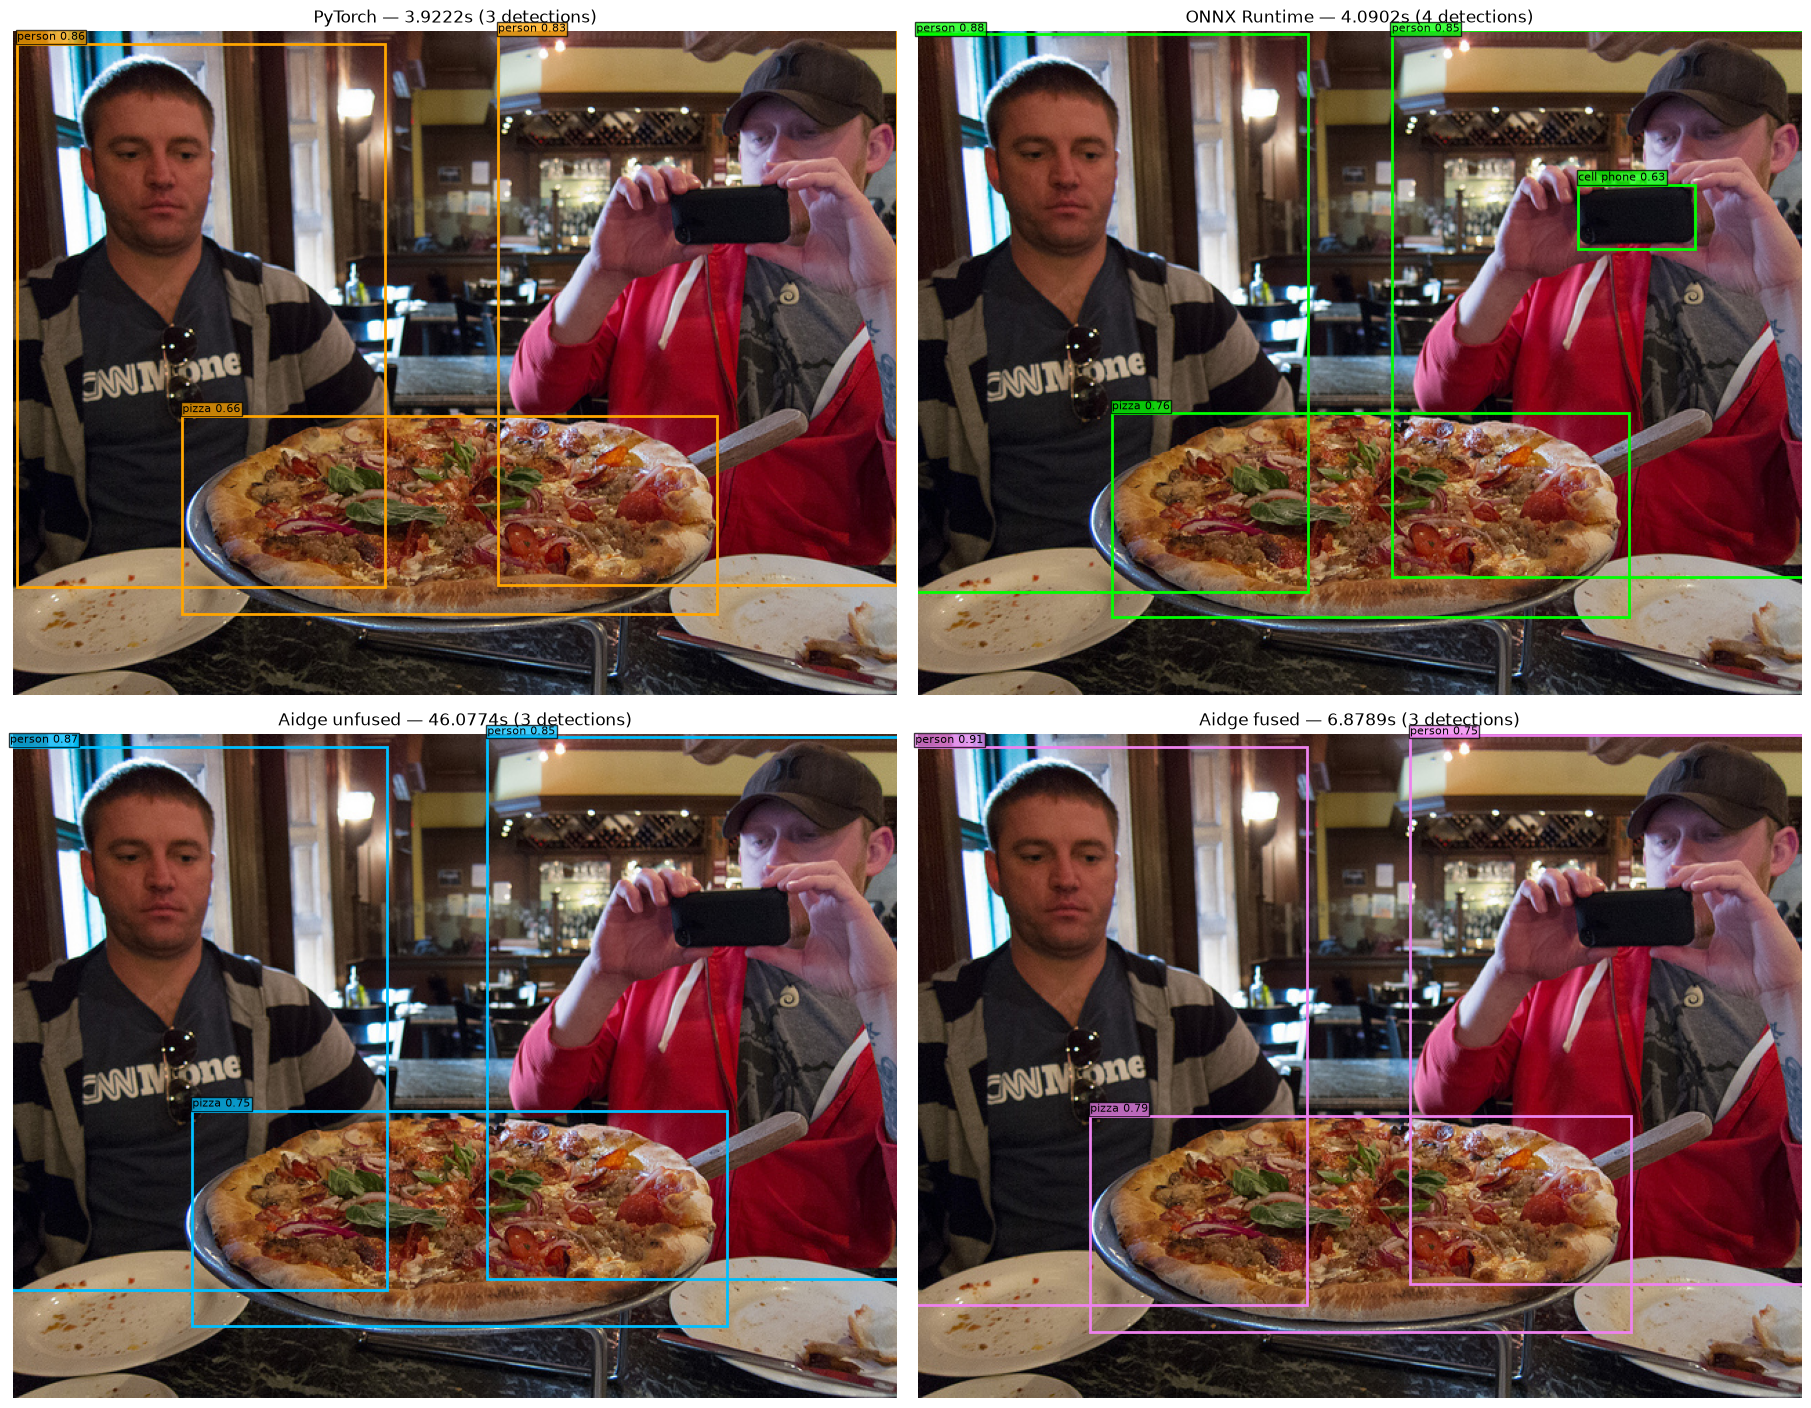

In [ ]:
profile_detections = {
    runtime: detections_from_outputs(outputs, image.size)
    for runtime, outputs in runtime_outputs.items()
}
colors = ('orange', 'lime', 'deepskyblue', 'violet')
fig, axes = plt.subplots(2, 2, figsize=(18, 14), constrained_layout=True)
for axis, (runtime, detections), color in zip(
    axes.flat, profile_detections.items(), colors
):
    draw(axis, detections, f'{runtime} — {timings[runtime]:.4f}s', color)
plt.show()

## Troubleshooting

- **`missing or invalid registrar key`**: confirm `aidge_backend_cpu` was imported and that the graph dtype has a registered kernel. Rebuild the backend after changing C++ kernel registrations.
- **No `SDShiftGELU`, `SDShiftSiLU`, or `SDShiftmax` nodes**: confirm you loaded the intended fake-quant ONNX model and called all three recipes before `set_backend()`. Restart the kernel after changing Python recipes; rebuild/reinstall `aidge_core` after changing C++ operators or bindings.
- **The dtype report still says `float32`**: this is expected for the current fake-quant ONNX data path. `forward_dtype(int8)` alone does not rewrite the graph into an end-to-end integer graph. The fused SD float adapters still perform their internal activation arithmetic using integer codes.
- **Unexpected fusion count**: the tiny model normally has 6 GELU blocks and 12 Shiftmax blocks. A different count can indicate a different checkpoint/export graph.
- **Aidge is slower than ONNX Runtime**: ONNX Runtime contains heavily optimized and fused CPU kernels. Use the profiling section to locate the actual bottleneck.
- **Outputs have the wrong names**: Aidge preserves graph connectivity, not necessarily ONNX output labels. This tutorial maps final outputs by unique shape and fails visibly when that mapping is ambiguous.